# 09 - Train & compare all four architectures on OrganAMNIST

Final subset of the project. Same four architectures, same pipeline — only `FLAG` changes. OrganAMNIST is grayscale (like PneumoniaMNIST) but multi-class and much larger (like DermaMNIST but with more data), which makes it a useful third data point: does more training data change the patterns seen so far (architecture ranking reversal between phases 1 and 2; severe sensitivity to class imbalance)?

In [1]:
import sys
sys.path.append("..")

import json
import time

import torch
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_dataloaders
from src.models import build_model
from src.train import train_model, evaluate_on_test
from src.utils import set_seed, get_device

set_seed(42)
device = get_device()
print("Using device:", device)


Using device: cuda


## 1. Load data

In [2]:
FLAG = "organamnist"
SIZE = 28
BATCH_SIZE = 128

loaders, spec = get_dataloaders(FLAG, size=SIZE, batch_size=BATCH_SIZE,
                                root="../data", use_train_stats=True)
print(spec)

DatasetSpec(flag='organamnist', task='multi-class', n_channels=1, n_classes=11, labels={'0': 'bladder', '1': 'femur-left', '2': 'femur-right', '3': 'heart', '4': 'kidney-left', '5': 'kidney-right', '6': 'liver', '7': 'lung-left', '8': 'lung-right', '9': 'pancreas', '10': 'spleen'})


## 2. Train all four models

OrganAMNIST has considerably more training images than the other two subsets, so expect this cell to take noticeably longer — plan accordingly.

In [3]:
MODEL_NAMES = ["simple_cnn", "resnet18", "vit", "medvit"]
results = {}
histories = {}

for name in MODEL_NAMES:
    print(f"\n{'='*60}\nTraining {name} on {FLAG}\n{'='*60}")
    model = build_model(name, n_channels=spec.n_channels, n_classes=spec.n_classes)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name}: {n_params:,} parameters")

    start = time.time()
    history = train_model(
        model, loaders, spec, device,
        epochs=15, lr=1e-3,
        out_dir="../results",
        run_name=f"{name}_{FLAG}",
        monitor="auc",
        early_stopping_patience=5,
    )
    elapsed = time.time() - start

    test_result = evaluate_on_test(model, loaders, spec, device,
                                   out_dir="../results", run_name=f"{name}_{FLAG}")
    results[name] = {**test_result.as_dict(), "n_params": n_params,
                     "train_time_s": round(elapsed, 1)}
    histories[name] = history
    print(f"{name} done in {elapsed/60:.1f} min")


Training simple_cnn on organamnist
simple_cnn: 24,235 parameters


simple_cnn_organamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[simple_cnn_organamnist] epoch 01 | train loss 1.0552 | val auc 0.9940 (best)
[simple_cnn_organamnist] epoch 02 | train loss 0.4512 | val auc 0.9982 (best)
[simple_cnn_organamnist] epoch 03 | train loss 0.3245 | val auc 0.9988 (best)
[simple_cnn_organamnist] epoch 04 | train loss 0.2657 | val auc 0.9989 (best)
[simple_cnn_organamnist] epoch 05 | train loss 0.2264 | val auc 0.9983
[simple_cnn_organamnist] epoch 06 | train loss 0.2027 | val auc 0.9988
[simple_cnn_organamnist] epoch 07 | train loss 0.1810 | val auc 0.9980
[simple_cnn_organamnist] epoch 08 | train loss 0.1673 | val auc 0.9994 (best)
[simple_cnn_organamnist] epoch 09 | train loss 0.1591 | val auc 0.9994 (best)
[simple_cnn_organamnist] epoch 10 | train loss 0.1409 | val auc 0.9992
[simple_cnn_organamnist] epoch 11 | train loss 0.1347 | val auc 0.9989
[simple_cnn_organamnist] epoch 12 | train loss 0.1272 | val auc 0.9995 (best)
[simple_cnn_organamnist] epoch 13 | train loss 0.1200 | val auc 0.9995
[simple_cnn_organamnist] epo

resnet18_organamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[resnet18_organamnist] epoch 01 | train loss 0.4215 | val auc 0.9968 (best)
[resnet18_organamnist] epoch 02 | train loss 0.1146 | val auc 0.9996 (best)
[resnet18_organamnist] epoch 03 | train loss 0.0637 | val auc 0.9995
[resnet18_organamnist] epoch 04 | train loss 0.0546 | val auc 0.9995
[resnet18_organamnist] epoch 05 | train loss 0.0340 | val auc 0.9994
[resnet18_organamnist] epoch 06 | train loss 0.0333 | val auc 0.9994
[resnet18_organamnist] epoch 07 | train loss 0.0217 | val auc 0.9997 (best)
[resnet18_organamnist] epoch 08 | train loss 0.0168 | val auc 0.9997 (best)
[resnet18_organamnist] epoch 09 | train loss 0.0221 | val auc 0.9992
[resnet18_organamnist] epoch 10 | train loss 0.0206 | val auc 0.9997
[resnet18_organamnist] epoch 11 | train loss 0.0257 | val auc 0.9997
[resnet18_organamnist] epoch 12 | train loss 0.0137 | val auc 0.9998 (best)
[resnet18_organamnist] epoch 13 | train loss 0.0026 | val auc 0.9995
[resnet18_organamnist] epoch 14 | train loss 0.0183 | val auc 0.9996

vit_organamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[vit_organamnist] epoch 01 | train loss 0.9356 | val auc 0.9899 (best)
[vit_organamnist] epoch 02 | train loss 0.4733 | val auc 0.9966 (best)
[vit_organamnist] epoch 03 | train loss 0.3200 | val auc 0.9990 (best)
[vit_organamnist] epoch 04 | train loss 0.2453 | val auc 0.9983
[vit_organamnist] epoch 05 | train loss 0.2063 | val auc 0.9990
[vit_organamnist] epoch 06 | train loss 0.1606 | val auc 0.9982
[vit_organamnist] epoch 07 | train loss 0.2000 | val auc 0.9990
[vit_organamnist] epoch 08 | train loss 0.1258 | val auc 0.9985
[vit_organamnist] no improvement in 5 epochs, stopping early at epoch 8.
[vit_organamnist] loaded best checkpoint from epoch 3 (val auc=0.9990)
[vit_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8497, balanced_accuracy=0.8438, auc=0.9857, f1=0.8450, majority_baseline_accuracy=0.1848)
vit done in 3.2 min

Training medvit on organamnist
medvit: 447,915 parameters


medvit_organamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[medvit_organamnist] epoch 01 | train loss 0.4778 | val auc 0.9967 (best)
[medvit_organamnist] epoch 02 | train loss 0.1747 | val auc 0.9994 (best)
[medvit_organamnist] epoch 03 | train loss 0.0796 | val auc 0.9977
[medvit_organamnist] epoch 04 | train loss 0.1209 | val auc 0.9991
[medvit_organamnist] epoch 05 | train loss 0.1331 | val auc 0.9993
[medvit_organamnist] epoch 06 | train loss 0.0456 | val auc 0.9981
[medvit_organamnist] epoch 07 | train loss 0.1188 | val auc 0.9992
[medvit_organamnist] no improvement in 5 epochs, stopping early at epoch 7.
[medvit_organamnist] loaded best checkpoint from epoch 2 (val auc=0.9994)
[medvit_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8835, balanced_accuracy=0.8817, auc=0.9909, f1=0.8765, majority_baseline_accuracy=0.1848)
medvit done in 2.8 min


## 3. Comparison table

In [4]:
comparison = pd.DataFrame(results).T
comparison = comparison[["n_params", "auc", "balanced_accuracy", "accuracy",
                         "f1", "train_time_s"]]
comparison.index.name = "model"
comparison

,n_params,auc,balanced_accuracy,accuracy,f1,train_time_s
model,,,,,,
simple_cnn,24235,0.993413,0.891632,0.898245,0.891462,323.6
resnet18,11173323,0.995896,0.913971,0.921138,0.914855,466.9
vit,139083,0.985688,0.843818,0.849702,0.844969,191.6
medvit,447915,0.990901,0.881689,0.883451,0.87651,169.5


## 4. AUC curves (validation) across models

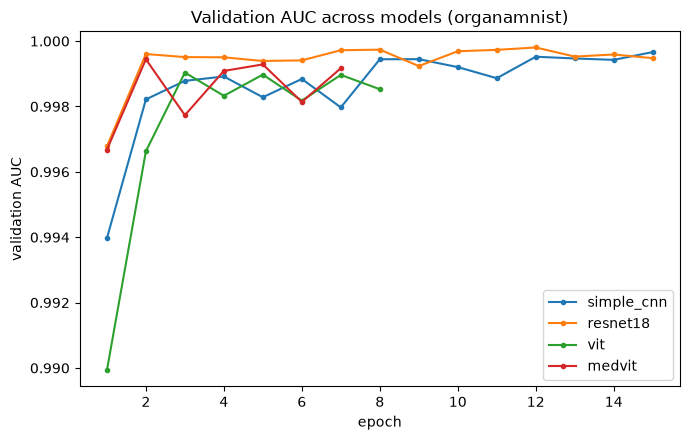

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in MODEL_NAMES:
    val_hist = histories[name]["val"]
    epochs_ran = [h["epoch"] for h in val_hist]
    ax.plot(epochs_ran, [h["auc"] for h in val_hist], label=name, marker="o", markersize=3)
ax.set_xlabel("epoch"); ax.set_ylabel("validation AUC"); ax.legend()
ax.set_title(f"Validation AUC across models ({FLAG})")
plt.tight_layout(); plt.show()

## 5. Confusion matrices (all four models)

Reloads each model's best checkpoint (already saved, no retraining) and plots the full 11x11 confusion matrix for each.

[simple_cnn_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8982, balanced_accuracy=0.8916, auc=0.9934, f1=0.8915, majority_baseline_accuracy=0.1848)
[resnet18_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.9211, balanced_accuracy=0.9140, auc=0.9959, f1=0.9149, majority_baseline_accuracy=0.1848)
[vit_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8497, balanced_accuracy=0.8438, auc=0.9857, f1=0.8450, majority_baseline_accuracy=0.1848)
[medvit_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8835, balanced_accuracy=0.8817, auc=0.9909, f1=0.8765, majority_baseline_accuracy=0.1848)


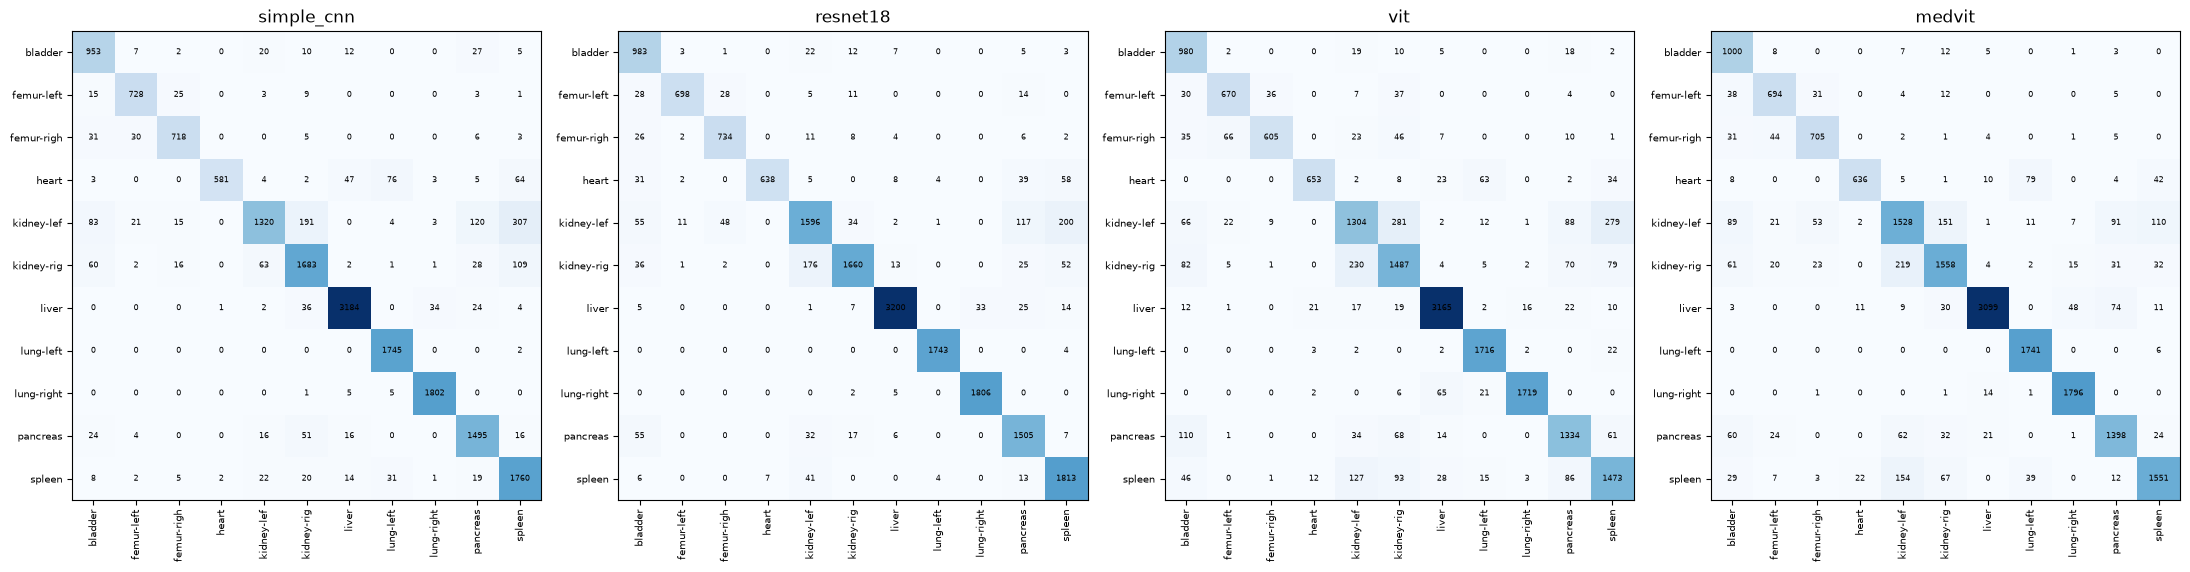

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
class_labels = [spec.labels[str(i)][:10] for i in range(spec.n_classes)]

for ax, name in zip(axes, MODEL_NAMES):
    model = build_model(name, n_channels=spec.n_channels, n_classes=spec.n_classes)
    model.load_state_dict(torch.load(f"../results/{name}_{FLAG}_best.pt", map_location=device))
    model.to(device)

    reeval = evaluate_on_test(model, loaders, spec, device,
                              out_dir="../results", run_name=f"{name}_{FLAG}")
    cm = reeval.confusion

    ax.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6)
    ax.set_xticks(range(spec.n_classes)); ax.set_xticklabels(class_labels, rotation=90, fontsize=7)
    ax.set_yticks(range(spec.n_classes)); ax.set_yticklabels(class_labels, fontsize=7)
    ax.set_title(name)

plt.tight_layout(); plt.show()

## 6. Recall per class

In [7]:
recall_table = {}
for name in MODEL_NAMES:
    model = build_model(name, n_channels=spec.n_channels, n_classes=spec.n_classes)
    model.load_state_dict(torch.load(f"../results/{name}_{FLAG}_best.pt", map_location=device))
    model.to(device)
    reeval = evaluate_on_test(model, loaders, spec, device,
                              out_dir="../results", run_name=f"{name}_{FLAG}")
    cm = reeval.confusion
    recall_table[name] = cm.diagonal() / cm.sum(axis=1)

recall_df = pd.DataFrame(recall_table, index=[spec.labels[str(i)] for i in range(spec.n_classes)])
recall_df.round(3)

[simple_cnn_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8982, balanced_accuracy=0.8916, auc=0.9934, f1=0.8915, majority_baseline_accuracy=0.1848)
[resnet18_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.9211, balanced_accuracy=0.9140, auc=0.9959, f1=0.9149, majority_baseline_accuracy=0.1848)
[vit_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8497, balanced_accuracy=0.8438, auc=0.9857, f1=0.8450, majority_baseline_accuracy=0.1848)
[medvit_organamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.8835, balanced_accuracy=0.8817, auc=0.9909, f1=0.8765, majority_baseline_accuracy=0.1848)


,simple_cnn,resnet18,vit,medvit
bladder,0.920,0.949,0.946,0.965
femur-left,0.929,0.890,0.855,0.885
femur-right,0.905,0.926,0.763,0.889
heart,0.740,0.813,0.832,0.810
kidney-left,0.640,0.773,0.632,0.740
kidney-right,0.856,0.845,0.757,0.793
liver,0.969,0.974,0.963,0.943
lung-left,0.999,0.998,0.982,0.997
lung-right,0.994,0.996,0.948,0.991
pancreas,0.922,0.928,0.822,0.862


## 7. Compare across all three subsets

The final comparison of the project: does the architecture ranking keep changing, settle into a pattern, or is each subset genuinely its own case?

In [8]:
all_results = {"organamnist": results}
for flag in ["pneumoniamnist", "dermamnist"]:
    all_results[flag] = {}
    for name in MODEL_NAMES:
        with open(f"../results/{name}_{flag}_test_metrics.json") as f:
            all_results[flag][name] = json.load(f)

auc_table = pd.DataFrame({
    flag: {name: all_results[flag][name]["auc"] for name in MODEL_NAMES}
    for flag in ["pneumoniamnist", "dermamnist", "organamnist"]
})
bal_acc_table = pd.DataFrame({
    flag: {name: all_results[flag][name]["balanced_accuracy"] for name in MODEL_NAMES}
    for flag in ["pneumoniamnist", "dermamnist", "organamnist"]
})
print("AUC across all three subsets:")
display(auc_table.round(4))
print("\nBalanced accuracy across all three subsets:")
display(bal_acc_table.round(4))

print("\nBest model per subset (by AUC):")
print(auc_table.idxmax())
print("\nBest model per subset (by balanced accuracy):")
print(bal_acc_table.idxmax())

AUC across all three subsets:


,pneumoniamnist,dermamnist,organamnist
simple_cnn,0.9681,0.9061,0.9934
resnet18,0.9534,0.9210,0.9959
vit,0.9567,0.9197,0.9857
medvit,0.9629,0.9097,0.9909



Balanced accuracy across all three subsets:


,pneumoniamnist,dermamnist,organamnist
simple_cnn,0.8248,0.3605,0.8916
resnet18,0.8393,0.5009,0.9140
vit,0.7500,0.4563,0.8438
medvit,0.7615,0.3808,0.8817



Best model per subset (by AUC):
pneumoniamnist    simple_cnn
dermamnist          resnet18
organamnist         resnet18
dtype: str

Best model per subset (by balanced accuracy):
pneumoniamnist    resnet18
dermamnist        resnet18
organamnist       resnet18
dtype: str


## 8. Observations

All four architectures reach balanced accuracy of 0.84-0.91 on OrganAMNIST,
versus 0.36-0.50 on DermaMNIST, despite OrganAMNIST having more classes (11
vs 7). The rarest OrganAMNIST class has 1,357 training images versus 80 in
DermaMNIST. This is consistent with absolute per-class example count being a
dominant factor, although it is confounded with task difficulty (organs are
visually far more distinct than skin lesions), so it is not isolated here.

ResNet-18 has the best balanced accuracy in all three subsets (0.839, 0.501,
0.914). AUC alone would have hidden this: on OrganAMNIST all AUCs fall
between 0.986 and 0.996, and on PneumoniaMNIST SimpleCNN had the highest AUC.
Gaps below ~0.01 are within the run-to-run variation observed when re-running
the notebooks (e.g. ResNet-18 balanced accuracy 0.9185 -> 0.9140).

MedViT beats plain ViT on OrganAMNIST by a clear margin in balanced accuracy
(0.882 vs 0.844) and loses on DermaMNIST (0.381 vs 0.456); on PneumoniaMNIST
the gap is close to noise.

The weakest class for every model is the left kidney (recall 0.63-0.77),
mostly confused with the right kidney and the spleen: anatomically adjacent
structures. These errors look different from DermaMNIST's, where rare classes
were largely ignored.